# Assessment 7: 1D, 2D and ND Analysis
**School of Computer Science and Engineering** | BCSE331P - Exploratory Data Analysis | Fall Semester 2026-27

Dataset: **BEPS**. `e1071::skewness/kurtosis` -> `scipy.stats.skew/kurtosis`; `aggregate()` -> `groupby().agg()`; `prop.table()` -> `crosstab(normalize=...)`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
from scipy import stats

## 1. Load the dataset

In [2]:
URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/BEPS.csv"
df = pd.read_csv(URL)

# BEPS has an unnamed row-index column -> drop it; replace '.' in names with '_' (easier in Python)
df = df.loc[:, ~df.columns.str.match(r"^(Unnamed.*|X|rownames)$")]
df.columns = df.columns.str.replace(".", "_", regex=False)
print("Shape:", df.shape)
df.head()

Shape: (1525, 10)


,vote,age,economic_cond_national,economic_cond_household,Blair,Hague,Kennedy,Europe,political_knowledge,gender
0,Liberal Democrat,43,3,3,4,1,4,2,2,female
1,Labour,36,4,4,4,4,4,5,2,male
2,Labour,35,4,4,5,2,3,3,2,male
3,Labour,24,4,2,2,1,3,4,0,female
4,Labour,41,2,2,1,1,4,6,2,male


In [3]:
df = df.dropna().reset_index(drop=True)
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.columns.difference(num_cols).tolist()
print("Numerical  :", num_cols)
print("Categorical:", cat_cols)

Numerical  : ['age', 'economic_cond_national', 'economic_cond_household', 'Blair', 'Hague', 'Kennedy', 'Europe', 'political_knowledge']
Categorical: ['gender', 'vote']


## 2-3. Summary statistics stored in a single data frame


In [4]:
def describe_stats(s):
    return {
        "Mean": s.mean(), "Median": s.median(), "Minimum": s.min(), "Maximum": s.max(),
        "Range": s.max() - s.min(), "Variance": s.var(), "Std Dev": s.std(),
        "IQR": s.quantile(0.75) - s.quantile(0.25),
        "Skewness": stats.skew(s), "Kurtosis": stats.kurtosis(s),
    }

summary_df = pd.DataFrame({col: describe_stats(df[col]) for col in num_cols}).T.round(4)
print(summary_df)

                            Mean  Median  Minimum  Maximum  Range  Variance  \
age                      54.1823    53.0     24.0     93.0   69.0  246.8421   
economic_cond_national    3.2459     3.0      1.0      5.0    4.0    0.7761   
economic_cond_household   3.1403     3.0      1.0      5.0    4.0    0.8648   
Blair                     3.3344     4.0      1.0      5.0    4.0    1.3802   
Hague                     2.7469     2.0      1.0      5.0    4.0    1.5146   
Kennedy                   3.1351     3.0      1.0      5.0    4.0    1.1707   
Europe                    6.7285     6.0      1.0     11.0   10.0   10.8738   
political_knowledge       1.5423     2.0      0.0      3.0    3.0    1.1736   

                         Std Dev   IQR  Skewness  Kurtosis  
age                      15.7112  26.0    0.1445   -0.9477  
economic_cond_national    0.8810   1.0   -0.2402   -0.2591  
economic_cond_household   0.9300   1.0   -0.1494   -0.2096  
Blair                     1.1748   2.0   -0.

## 4. Frequency & relative-frequency table of a categorical variable, Pie chart and Bar plot

,Frequency,Relative Frequency,Percent
vote,,,
Labour,720,0.4721,47.21
Conservative,462,0.3030,30.30
Liberal Democrat,343,0.2249,22.49


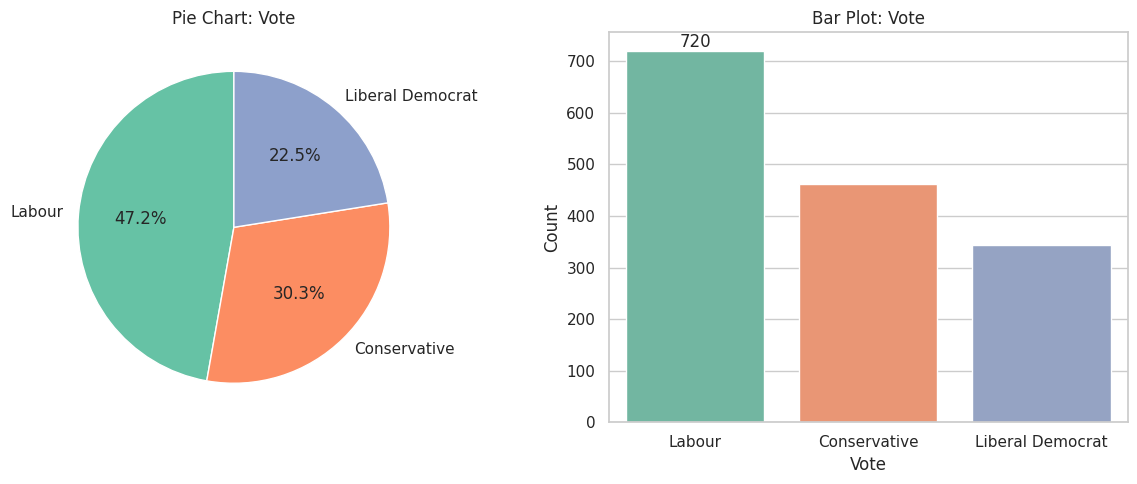

In [5]:
freq = df["vote"].value_counts()
freq_table = pd.DataFrame({"Frequency": freq, "Relative Frequency": (freq / freq.sum()).round(4)})
freq_table["Percent"] = (freq_table["Relative Frequency"] * 100).round(2)
display(freq_table)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].pie(freq, labels=freq.index, autopct="%1.1f%%", startangle=90, colors=sns.color_palette("Set2"))
axes[0].set_title("Pie Chart: Vote")
sns.barplot(x=freq.index, y=freq.values, palette="Set2", ax=axes[1])
axes[1].bar_label(axes[1].containers[0])
axes[1].set(title="Bar Plot: Vote", xlabel="Vote", ylabel="Count")
plt.tight_layout()
plt.show()

## 5. Binned frequency table, Histogram and Box plot for a numerical variable (`age`)

,Age interval,Frequency,Relative Frequency,Cumulative Freq
0,"[20, 30)",62,0.0407,62
1,"[30, 40)",277,0.1816,339
2,"[40, 50)",307,0.2013,646
3,"[50, 60)",298,0.1954,944
4,"[60, 70)",263,0.1725,1207
5,"[70, 80)",240,0.1574,1447
6,"[80, 90)",73,0.0479,1520
7,"[90, 100)",5,0.0033,1525


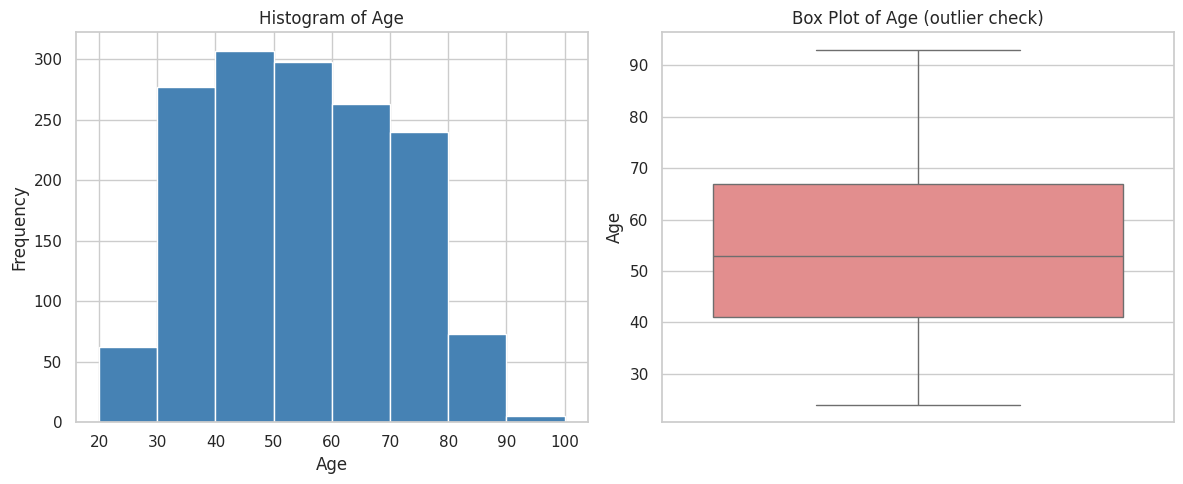

In [6]:
lo = int(np.floor(df["age"].min() / 10) * 10)
hi = int(np.ceil((df["age"].max() + 1) / 10) * 10)
bins = np.arange(lo, hi + 1, 10)

age_bins = pd.cut(df["age"], bins=bins, right=False)
bin_table = age_bins.value_counts().sort_index().rename_axis("Age interval").reset_index(name="Frequency")
bin_table["Relative Frequency"] = (bin_table["Frequency"] / bin_table["Frequency"].sum()).round(4)
bin_table["Cumulative Freq"] = bin_table["Frequency"].cumsum()
display(bin_table)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hist(df["age"], bins=bins, color="steelblue", edgecolor="white")
axes[0].set(title="Histogram of Age", xlabel="Age", ylabel="Frequency")
sns.boxplot(y=df["age"], color="lightcoral", ax=axes[1])
axes[1].set(title="Box Plot of Age (outlier check)", ylabel="Age")
plt.tight_layout()
plt.show()

## 6. Contingency table (`vote` x `gender`) with row / column percentages (`prop.table`)

In [7]:
ct = pd.crosstab(df["vote"], df["gender"])
print("Contingency table (counts):")
display(ct)
print("Row percentages (each vote adds to 100%):")
display((pd.crosstab(df["vote"], df["gender"], normalize="index") * 100).round(2))
print("Column percentages (each gender adds to 100%):")
display((pd.crosstab(df["vote"], df["gender"], normalize="columns") * 100).round(2))
print("Overall proportions:")
display(pd.crosstab(df["vote"], df["gender"], normalize="all").round(4))

Contingency table (counts):


gender,female,male
vote,,
Conservative,259,203
Labour,372,348
Liberal Democrat,181,162


Row percentages (each vote adds to 100%):


gender,female,male
vote,,
Conservative,56.06,43.94
Labour,51.67,48.33
Liberal Democrat,52.77,47.23


Column percentages (each gender adds to 100%):


gender,female,male
vote,,
Conservative,31.90,28.47
Labour,45.81,48.81
Liberal Democrat,22.29,22.72


Overall proportions:


gender,female,male
vote,,
Conservative,0.1698,0.1331
Labour,0.2439,0.2282
Liberal Democrat,0.1187,0.1062


## 7. Stacked and grouped bar plots

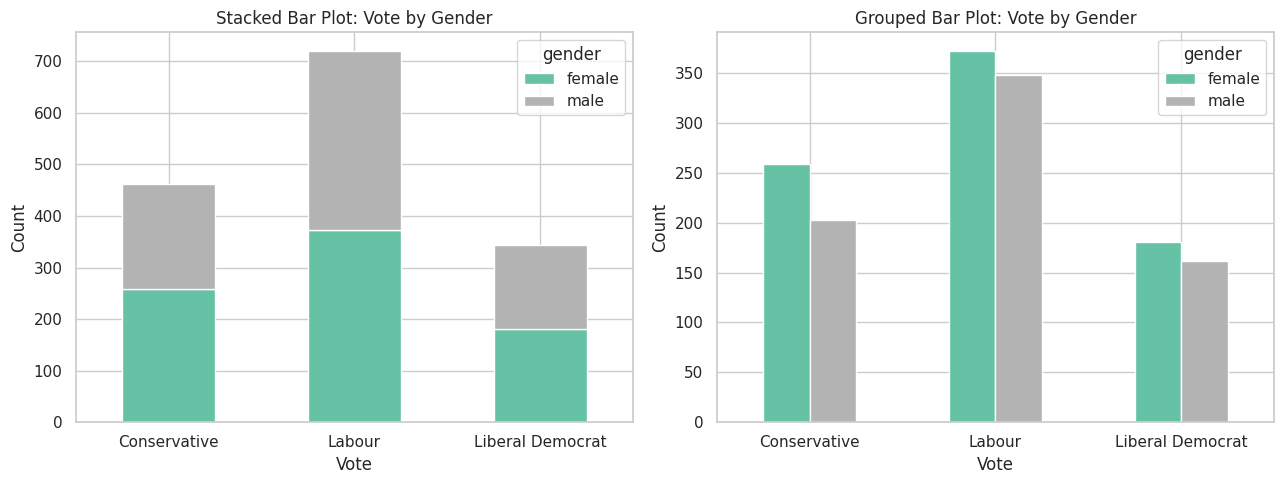

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ct.plot(kind="bar", stacked=True, ax=axes[0], rot=0, colormap="Set2")
axes[0].set(title="Stacked Bar Plot: Vote by Gender", xlabel="Vote", ylabel="Count")
ct.plot(kind="bar", stacked=False, ax=axes[1], rot=0, colormap="Set2")
axes[1].set(title="Grouped Bar Plot: Vote by Gender", xlabel="Vote", ylabel="Count")
plt.tight_layout()
plt.show()

## 8. Mean, median and SD of `age` for each `vote` (R `aggregate()`)

In [9]:
agg = df.groupby("vote")["age"].agg(["mean", "median", "std"]).round(3)
agg

,mean,median,std
vote,,,
Conservative,56.870,58.0,15.606
Labour,53.004,51.0,15.797
Liberal Democrat,53.035,51.0,15.265


## 9. Side-by-side box plots and violin plot

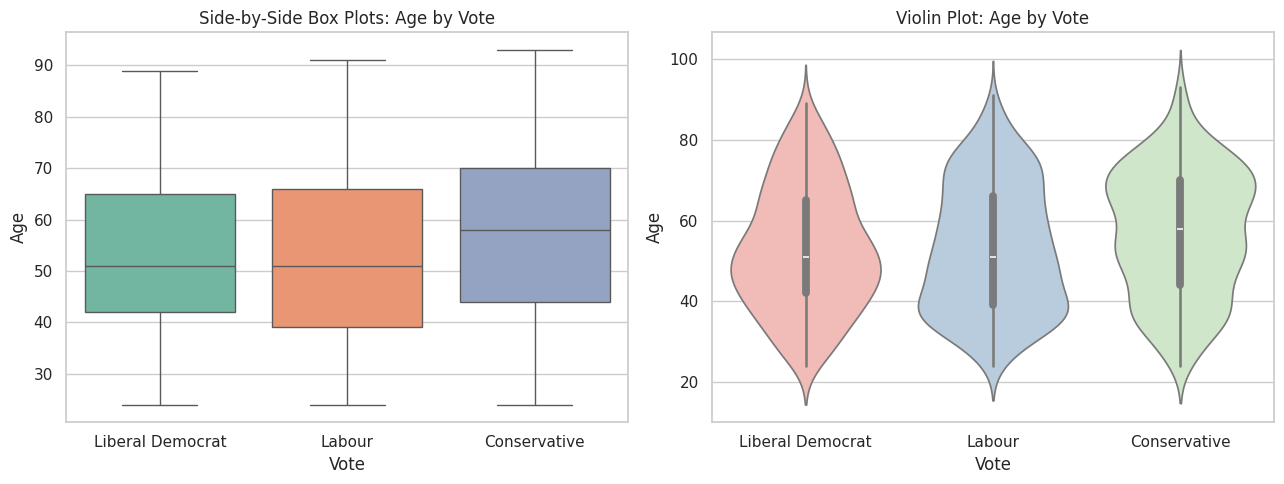

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df, x="vote", y="age", palette="Set2", ax=axes[0])
axes[0].set(title="Side-by-Side Box Plots: Age by Vote", xlabel="Vote", ylabel="Age")
sns.violinplot(data=df, x="vote", y="age", palette="Pastel1", ax=axes[1])
axes[1].set(title="Violin Plot: Age by Vote", xlabel="Vote", ylabel="Age")
plt.tight_layout()
plt.show()

## 10. Pearson & Spearman correlation and scatter plot with a linear trend line (`Blair` vs `Hague`)

Pearson  r = -0.2432 (p = 5.69e-22)  | pandas: -0.2432
Spearman r = -0.2397 (p = 2.24e-21)  | pandas: -0.2397


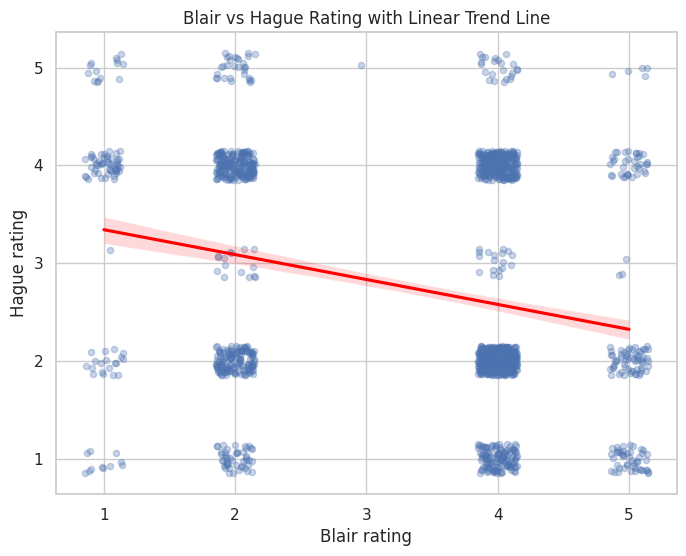

In [11]:
x, y = df["Blair"], df["Hague"]
pear_r, pear_p = stats.pearsonr(x, y)
spear_r, spear_p = stats.spearmanr(x, y)
print(f"Pearson  r = {pear_r:.4f} (p = {pear_p:.3g})  | pandas: {x.corr(y, method='pearson'):.4f}")
print(f"Spearman r = {spear_r:.4f} (p = {spear_p:.3g})  | pandas: {x.corr(y, method='spearman'):.4f}")

fig, ax = plt.subplots(figsize=(8, 6))
sns.regplot(data=df, x="Blair", y="Hague", x_jitter=0.15, y_jitter=0.15,
            scatter_kws={"alpha": 0.3, "s": 20}, line_kws={"color": "red"}, ax=ax)
ax.set(title="Blair vs Hague Rating with Linear Trend Line", xlabel="Blair rating", ylabel="Hague rating")
plt.show()

## 11. Two categorical + one numerical (`vote`, `gender`, `age`)

mean     std
vote             gender                
Conservative     female  58.293  15.902
                 male    55.054  15.063
Labour           female  52.543  15.909
                 male    53.497  15.685
Liberal Democrat female  52.972  15.547
                 male    53.105  14.993

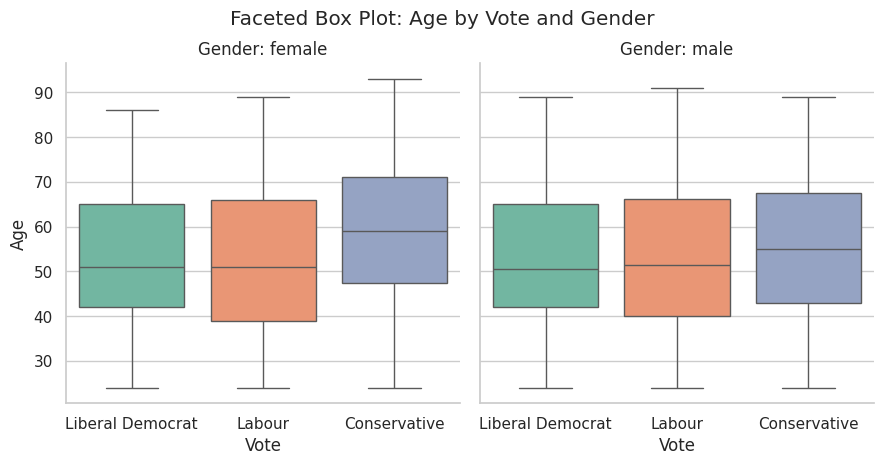

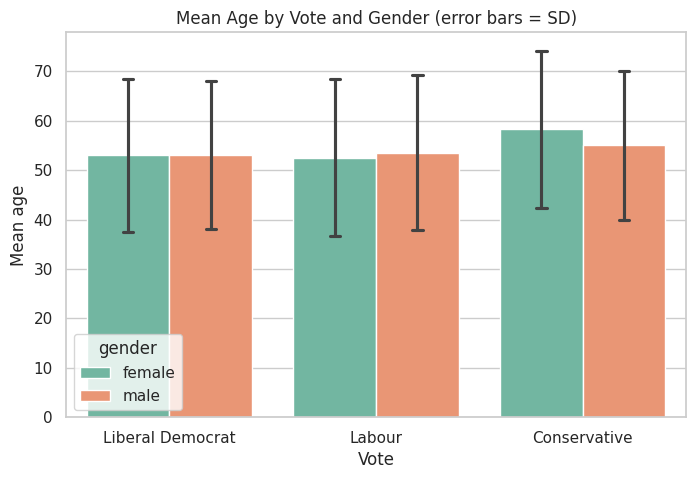

In [12]:
combo = df.groupby(["vote", "gender"])["age"].agg(["mean", "std"]).round(3)
display(combo)

g = sns.catplot(data=df, x="vote", y="age", col="gender", kind="box", palette="Set2", height=4.5, aspect=1)
g.set_axis_labels("Vote", "Age")
g.set_titles("Gender: {col_name}")
g.figure.suptitle("Faceted Box Plot: Age by Vote and Gender", y=1.03)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=df, x="vote", y="age", hue="gender", errorbar="sd", capsize=0.1, palette="Set2", ax=ax)
ax.set(title="Mean Age by Vote and Gender (error bars = SD)", xlabel="Vote", ylabel="Mean age")
plt.show()

## 12. One categorical + two numerical (`vote`, `age`, `Europe`)

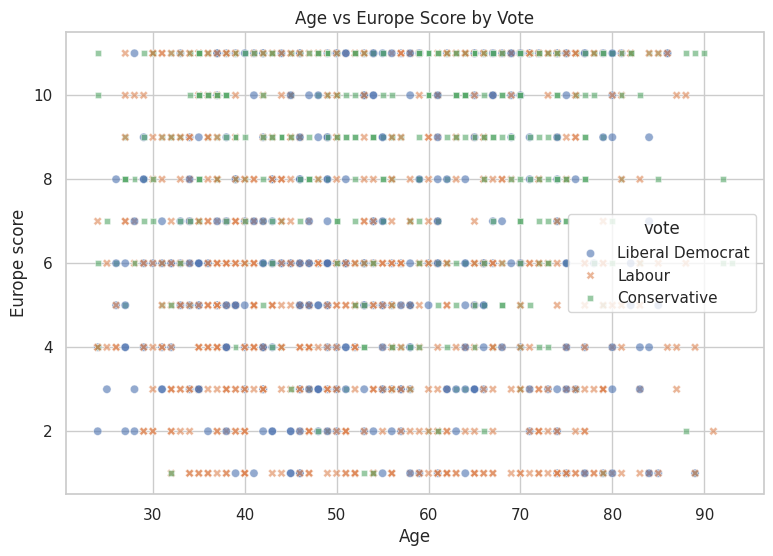

Correlation between age and Europe for each vote category:

--- Conservative ---


,age,Europe
age,1.000,0.044
Europe,0.044,1.000



--- Labour ---


,age,Europe
age,1.000,-0.005
Europe,-0.005,1.000



--- Liberal Democrat ---


,age,Europe
age,1.000,0.084
Europe,0.084,1.000


In [13]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=df, x="age", y="Europe", hue="vote", style="vote", alpha=0.6, ax=ax)
ax.set(title="Age vs Europe Score by Vote", xlabel="Age", ylabel="Europe score")
plt.show()

print("Correlation between age and Europe for each vote category:")
for level, grp in df.groupby("vote"):
    print(f"\n--- {level} ---")
    display(grp[["age", "Europe"]].corr().round(3))

## 13. Correlation matrix and heatmap (all numerical features)

,age,economic_cond_national,economic_cond_household,Blair,Hague,Kennedy,Europe,political_knowledge
age,1.000,0.019,-0.042,0.030,0.035,0.004,0.069,-0.048
economic_cond_national,0.019,1.000,0.346,0.327,-0.200,0.097,-0.209,-0.024
economic_cond_household,-0.042,0.346,1.000,0.215,-0.102,0.040,-0.115,-0.038
Blair,0.030,0.327,0.215,1.000,-0.243,0.148,-0.296,-0.021
Hague,0.035,-0.200,-0.102,-0.243,1.000,-0.080,0.287,-0.030
Kennedy,0.004,0.097,0.040,0.148,-0.080,1.000,-0.110,0.001
Europe,0.069,-0.209,-0.115,-0.296,0.287,-0.110,1.000,-0.152
political_knowledge,-0.048,-0.024,-0.038,-0.021,-0.030,0.001,-0.152,1.000


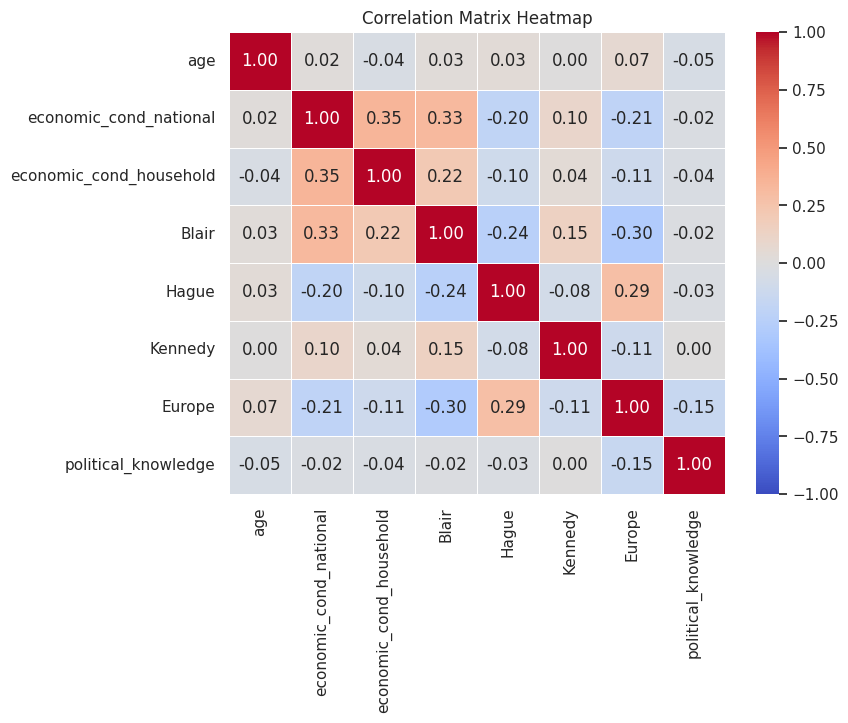

In [14]:
corr = df[num_cols].corr()
display(corr.round(3))
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5, ax=ax)
ax.set_title("Correlation Matrix Heatmap")
plt.show()

## 14. Pairs plot / scatterplot matrix

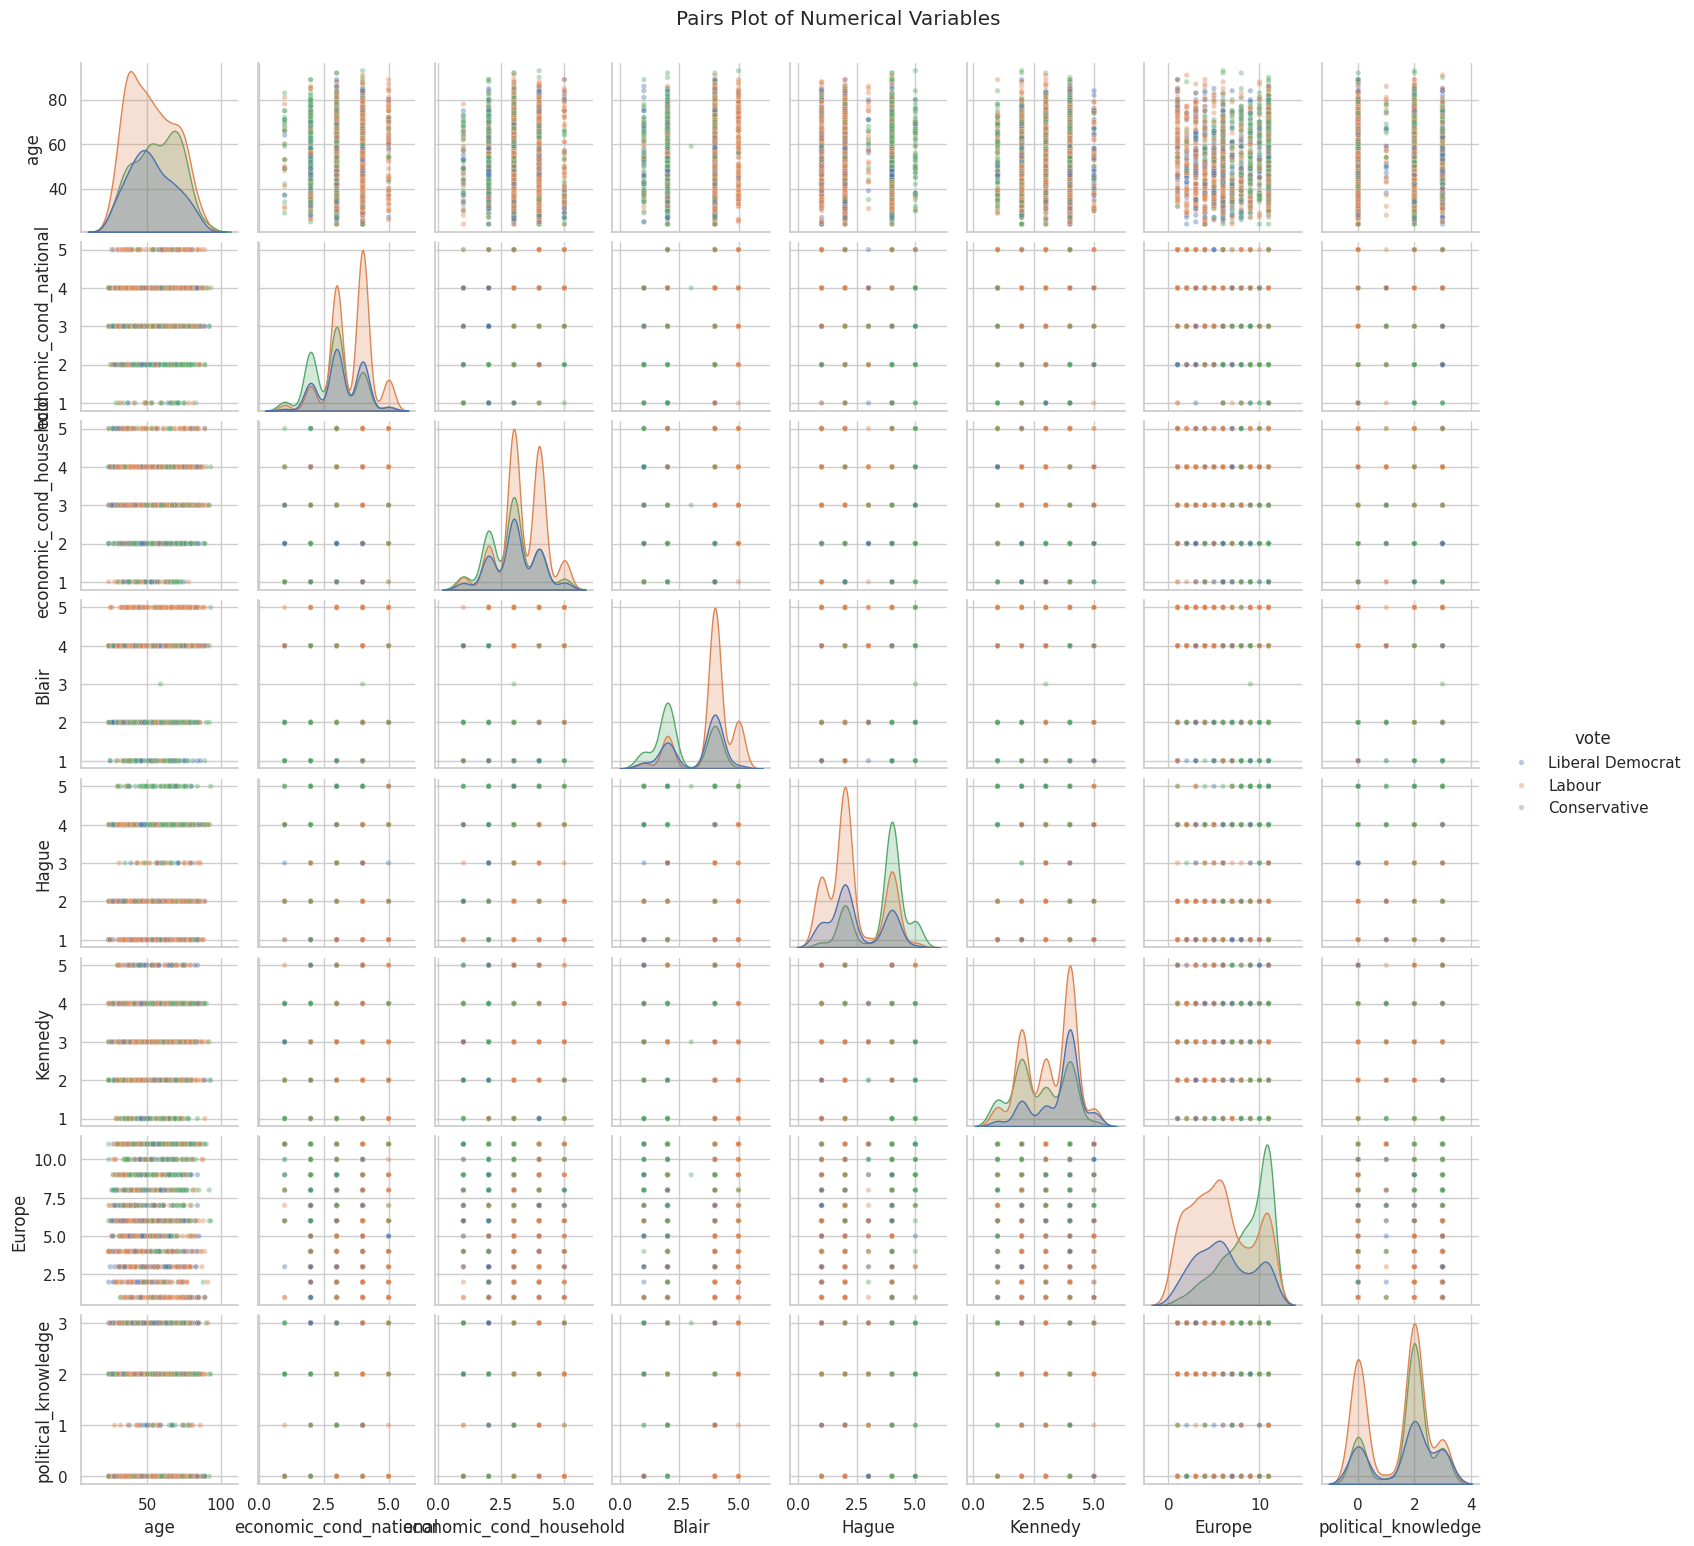

In [15]:
g = sns.pairplot(df[num_cols + ["vote"]], hue="vote", diag_kind="kde",
                 plot_kws={"alpha": 0.4, "s": 15}, height=1.9)
g.figure.suptitle("Pairs Plot of Numerical Variables", y=1.02)
plt.show()